# 07B — Diagnostic of the f02 verification problem

## Objective

Notebook 07 produced a strong frozen detector overall, but `f02` behaved very differently from the
other classes:

- identification was mostly correct;
- the selected one-vs-all LLR threshold rejected many true `f02` calls;
- `f02` AUROC was much lower than the other species.

This notebook **does not retrain models and does not modify any saved threshold**.

Its only purpose is to diagnose why `f02` is difficult before any threshold is changed.

## Questions

1. How do positive and negative `LLR_f02` distributions overlap?
2. Which true species generate the largest false `f02` LLR values?
3. Are the rejected true `f02` calls concentrated in one source WAV?
4. When a true `f02` call is rejected, was `f02` still the winning GMM?
5. Which alternative GMMs are closest to `f02`?
6. What recall/FPR trade-off would result from alternative `f02` thresholds?

## Important rule

All threshold sweeps below are **diagnostic only**. The frozen detector from notebook 07 remains
unchanged until the evidence supports a specific change.

In [11]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 190)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 120)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

CALIBRATION_DIR = (
    REPO_ROOT
    / "data"
    / "processed"
    / "final_detector_calibration"
)

MODEL_DIR = (
    REPO_ROOT
    / "models"
    / "gmm_robust_final"
)

RESULTS_DIR = (
    CALIBRATION_DIR
    / "f02_diagnostic"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SCORES_PATH = (
    CALIBRATION_DIR
    / "calibration_scores_and_llr.csv"
)

DECISIONS_PATH = (
    CALIBRATION_DIR
    / "calibration_detector_decisions.csv"
)

THRESHOLDS_PATH = (
    CALIBRATION_DIR
    / "thresholds_and_roc_operating_points.csv"
)

CALIBRATION_CALLS_PATH = (
    CALIBRATION_DIR
    / "calibration_calls.csv"
)

THRESHOLD_JSON_PATH = (
    MODEL_DIR
    / "thresholds.json"
)

for path in (
    SCORES_PATH,
    DECISIONS_PATH,
    THRESHOLDS_PATH,
    CALIBRATION_CALLS_PATH,
    THRESHOLD_JSON_PATH,
):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing required notebook-07 output: {path}"
        )

print("Calibration outputs:", CALIBRATION_DIR)
print("Diagnostic outputs :", RESULTS_DIR)

Calibration outputs: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\final_detector_calibration
Diagnostic outputs : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\final_detector_calibration\f02_diagnostic


## 2. Load notebook-07 outputs

The diagnostic uses the scores already produced by the frozen GMMs. No feature extraction and no model
fitting occurs here.

In [12]:
scores = pd.read_csv(
    SCORES_PATH
)

decisions = pd.read_csv(
    DECISIONS_PATH
)

threshold_table = pd.read_csv(
    THRESHOLDS_PATH
)

calibration_calls = pd.read_csv(
    CALIBRATION_CALLS_PATH
)

with open(
    THRESHOLD_JSON_PATH,
    "r",
    encoding="utf-8",
) as f:
    thresholds = json.load(f)

TARGET_CODE = "f02"

F02_THRESHOLD = float(
    thresholds[
        TARGET_CODE
    ]
)

required_score_columns = {
    "call_id",
    "true_code",
    "hypothesis",
    "recording_group",
    f"score_{TARGET_CODE}",
    f"llr_{TARGET_CODE}",
}

missing = (
    required_score_columns
    - set(scores.columns)
)

if missing:
    raise ValueError(
        f"Missing required score columns: {sorted(missing)}"
    )

print("Calibration calls:", len(scores))
print("f02 threshold    :", F02_THRESHOLD)
print(
    "True f02 calls   :",
    int(
        (
            scores["true_code"]
            == TARGET_CODE
        ).sum()
    ),
)

Calibration calls: 382
f02 threshold    : 8.581322506789903
True f02 calls   : 24


## 3. Positive versus negative f02 LLR distributions

For the `f02` one-vs-all problem:

- positive = true species is `f02`;
- negative = any other modelled species.

A useful threshold needs to separate these two score distributions.

In [13]:
f02_scores = (
    scores[
        [
            "call_id",
            "true_code",
            "species",
            "wav",
            "recording_group",
            "hypothesis",
            "identification_correct",
            f"score_{TARGET_CODE}",
            f"llr_{TARGET_CODE}",
        ]
    ]
    .copy()
)

f02_scores["is_f02"] = (
    f02_scores[
        "true_code"
    ] == TARGET_CODE
)

f02_scores["passes_current_threshold"] = (
    f02_scores[
        f"llr_{TARGET_CODE}"
    ]
    >= F02_THRESHOLD
)

distribution_summary = (
    f02_scores
    .groupby(
        "is_f02",
        as_index=False,
    )
    .agg(
        n=(
            "call_id",
            "size",
        ),
        llr_min=(
            f"llr_{TARGET_CODE}",
            "min",
        ),
        llr_q10=(
            f"llr_{TARGET_CODE}",
            lambda x: x.quantile(0.10),
        ),
        llr_q25=(
            f"llr_{TARGET_CODE}",
            lambda x: x.quantile(0.25),
        ),
        llr_median=(
            f"llr_{TARGET_CODE}",
            "median",
        ),
        llr_q75=(
            f"llr_{TARGET_CODE}",
            lambda x: x.quantile(0.75),
        ),
        llr_q90=(
            f"llr_{TARGET_CODE}",
            lambda x: x.quantile(0.90),
        ),
        llr_max=(
            f"llr_{TARGET_CODE}",
            "max",
        ),
        pass_rate=(
            "passes_current_threshold",
            "mean",
        ),
    )
)

distribution_summary[
    "group"
] = np.where(
    distribution_summary[
        "is_f02"
    ],
    "positive_true_f02",
    "negative_other_species",
)

display(
    distribution_summary[
        [
            "group",
            "n",
            "llr_min",
            "llr_q10",
            "llr_q25",
            "llr_median",
            "llr_q75",
            "llr_q90",
            "llr_max",
            "pass_rate",
        ]
    ].round(4)
)

,group,n,llr_min,llr_q10,llr_q25,llr_median,llr_q75,llr_q90,llr_max,pass_rate
0,negative_other_species,358,-2.9518,-0.9467,0.0344,1.8989,6.1672,7.0783,9.9249,0.0056
1,positive_true_f02,24,3.2508,3.9277,4.7653,5.8580,6.2163,7.9112,9.8685,0.1250


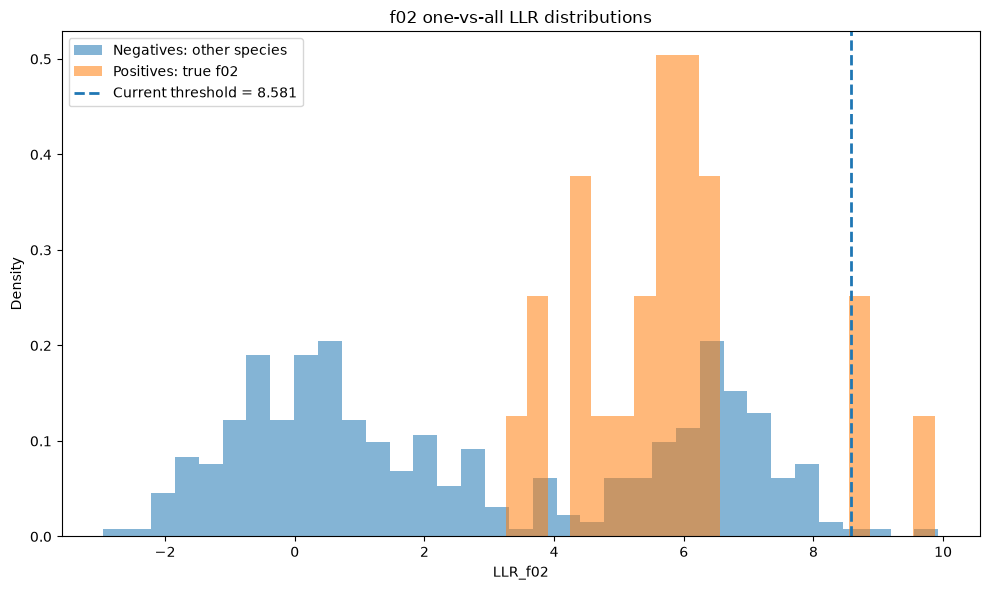

In [14]:
positive_llr = (
    f02_scores.loc[
        f02_scores[
            "is_f02"
        ],
        f"llr_{TARGET_CODE}",
    ]
)

negative_llr = (
    f02_scores.loc[
        ~f02_scores[
            "is_f02"
        ],
        f"llr_{TARGET_CODE}",
    ]
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.hist(
    negative_llr,
    bins=35,
    alpha=0.55,
    density=True,
    label="Negatives: other species",
)

ax.hist(
    positive_llr,
    bins=20,
    alpha=0.55,
    density=True,
    label="Positives: true f02",
)

ax.axvline(
    F02_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Current threshold = {F02_THRESHOLD:.3f}",
)

ax.set(
    title="f02 one-vs-all LLR distributions",
    xlabel="LLR_f02",
    ylabel="Density",
)

ax.legend()

plt.tight_layout()
plt.show()

## 4. Which species produce the largest negative f02 scores?

This is the most direct way to identify the classes that force the `f02` threshold upward.

In [15]:
negative_by_species = (
    f02_scores[
        ~f02_scores[
            "is_f02"
        ]
    ]
    .groupby(
        "true_code",
        as_index=False,
    )
    .agg(
        n=(
            "call_id",
            "size",
        ),
        llr_mean=(
            f"llr_{TARGET_CODE}",
            "mean",
        ),
        llr_median=(
            f"llr_{TARGET_CODE}",
            "median",
        ),
        llr_q90=(
            f"llr_{TARGET_CODE}",
            lambda x: x.quantile(0.90),
        ),
        llr_q95=(
            f"llr_{TARGET_CODE}",
            lambda x: x.quantile(0.95),
        ),
        llr_max=(
            f"llr_{TARGET_CODE}",
            "max",
        ),
        n_above_current_threshold=(
            "passes_current_threshold",
            "sum",
        ),
        fraction_above_current_threshold=(
            "passes_current_threshold",
            "mean",
        ),
    )
    .sort_values(
        [
            "llr_max",
            "llr_q95",
        ],
        ascending=False,
    )
)

display(
    negative_by_species.round(4)
)

,true_code,n,llr_mean,llr_median,llr_q90,llr_q95,llr_max,n_above_current_threshold,fraction_above_current_threshold
3,f05,135,6.5056,6.4728,7.7480,7.9134,9.9249,2,0.0148
1,f03,26,2.6199,2.7244,3.8202,4.1723,4.8377,0,0.0000
2,f04,47,0.8961,0.7112,2.0540,2.3002,3.8334,0,0.0000
0,f01,19,2.2496,2.0892,3.0703,3.2382,3.8002,0,0.0000
7,f10,76,-0.3947,-0.5241,0.8273,2.0083,3.7863,0,0.0000
6,f08,25,0.4049,0.4956,1.2274,1.3939,1.4499,0,0.0000
4,f06,13,-0.7009,-0.4865,-0.0267,0.0834,0.2017,0,0.0000
5,f07,17,-0.6577,-0.8012,0.0432,0.0870,0.1266,0,0.0000


In [16]:
top_negative_calls = (
    f02_scores[
        ~f02_scores[
            "is_f02"
        ]
    ]
    .sort_values(
        f"llr_{TARGET_CODE}",
        ascending=False,
    )
    .head(30)
)

display(
    top_negative_calls[
        [
            "call_id",
            "true_code",
            "wav",
            "recording_group",
            "hypothesis",
            f"score_{TARGET_CODE}",
            f"llr_{TARGET_CODE}",
            "passes_current_threshold",
        ]
    ].round(4)
)

,call_id,true_code,wav,recording_group,hypothesis,score_f02,llr_f02,passes_current_threshold
137,call_0778,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f02,26.0466,9.9249,True
133,call_0774,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f02,25.8870,9.1595,True
208,call_0849,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f05,30.3151,8.5241,False
204,call_0845,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f05,30.0556,8.4512,False
184,call_0825,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f05,29.4660,8.1358,False
242,call_0883,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f10,25.3087,7.9983,False
223,call_0864,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f05,31.1590,7.9751,False
247,call_0888,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f05,27.2233,7.8870,False
235,call_0876,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f05,27.4076,7.8811,False
182,call_0823,f05,LS100171 L. andreae no capturado Limoncocha.WAV,ls100171 l. andreae no capturado limoncocha.wav,f05,28.4568,7.8716,False


## 5. True f02 calls: identification versus verification

A false negative may arise for two fundamentally different reasons:

1. **identification error:** another GMM wins;
2. **verification rejection:** `f02` wins, but `LLR_f02` is below the threshold.

Those two failure modes should not be mixed.

In [17]:
true_f02 = (
    f02_scores[
        f02_scores[
            "is_f02"
        ]
    ]
    .copy()
)

true_f02["f02_is_winner"] = (
    true_f02[
        "hypothesis"
    ] == TARGET_CODE
)

true_f02["failure_mode"] = np.select(
    [
        ~true_f02[
            "f02_is_winner"
        ],
        (
            true_f02[
                "f02_is_winner"
            ]
            & ~true_f02[
                "passes_current_threshold"
            ]
        ),
        (
            true_f02[
                "f02_is_winner"
            ]
            & true_f02[
                "passes_current_threshold"
            ]
        ),
    ],
    [
        "identification_error",
        "verification_rejection",
        "accepted_true_f02",
    ],
    default="unexpected",
)

failure_counts = (
    true_f02[
        "failure_mode"
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "failure_mode"
    )
    .reset_index(
        name="n_calls"
    )
)

display(
    failure_counts
)

display(
    true_f02[
        [
            "call_id",
            "wav",
            "recording_group",
            "hypothesis",
            f"llr_{TARGET_CODE}",
            "passes_current_threshold",
            "failure_mode",
        ]
    ]
    .sort_values(
        f"llr_{TARGET_CODE}"
    )
    .round(4)
)

,failure_mode,n_calls
0,verification_rejection,19
1,accepted_true_f02,3
2,identification_error,2


,call_id,wav,recording_group,hypothesis,llr_f02,passes_current_threshold,failure_mode
26,call_0172,LS100584.WAV,ls100584.wav,f05,3.2508,False,identification_error
33,call_0179,LS100584.WAV,ls100584.wav,f02,3.7012,False,verification_rejection
31,call_0177,LS100584.WAV,ls100584.wav,f02,3.7491,False,verification_rejection
39,call_0185,LS100584.WAV,ls100584.wav,f02,4.3445,False,verification_rejection
27,call_0173,LS100584.WAV,ls100584.wav,f02,4.3447,False,verification_rejection
36,call_0182,LS100584.WAV,ls100584.wav,f02,4.5424,False,verification_rejection
37,call_0183,LS100584.WAV,ls100584.wav,f02,4.8396,False,verification_rejection
30,call_0176,LS100584.WAV,ls100584.wav,f02,5.0923,False,verification_rejection
24,call_0170,LS100584.WAV,ls100584.wav,f05,5.3631,False,identification_error
38,call_0184,LS100584.WAV,ls100584.wav,f02,5.5249,False,verification_rejection


## 6. Is the f02 problem concentrated in one recording?

Because the robust protocol is grouped by WAV, a calibration species may be represented by only a few
independent recordings. A low threshold pass rate can therefore be caused by a specific unseen acoustic
condition rather than by every `f02` recording equally.

In [18]:
f02_by_recording = (
    true_f02
    .groupby(
        [
            "recording_group",
            "wav",
        ],
        as_index=False,
    )
    .agg(
        n_calls=(
            "call_id",
            "size",
        ),
        llr_min=(
            f"llr_{TARGET_CODE}",
            "min",
        ),
        llr_median=(
            f"llr_{TARGET_CODE}",
            "median",
        ),
        llr_mean=(
            f"llr_{TARGET_CODE}",
            "mean",
        ),
        llr_max=(
            f"llr_{TARGET_CODE}",
            "max",
        ),
        identification_rate=(
            "f02_is_winner",
            "mean",
        ),
        threshold_pass_rate=(
            "passes_current_threshold",
            "mean",
        ),
    )
    .sort_values(
        "llr_median"
    )
)

display(
    f02_by_recording.round(4)
)

,recording_group,wav,n_calls,llr_min,llr_median,llr_mean,llr_max,identification_rate,threshold_pass_rate
1,ls100584.wav,LS100584.WAV,21,3.2508,5.7098,5.3010,6.3477,0.9048,0.0
0,d-bifircus-d-parviceps-ls100120.wav,D-bifircus-D-parviceps-LS100120.WAV,3,8.5813,8.8297,9.0932,9.8685,1.0000,1.0


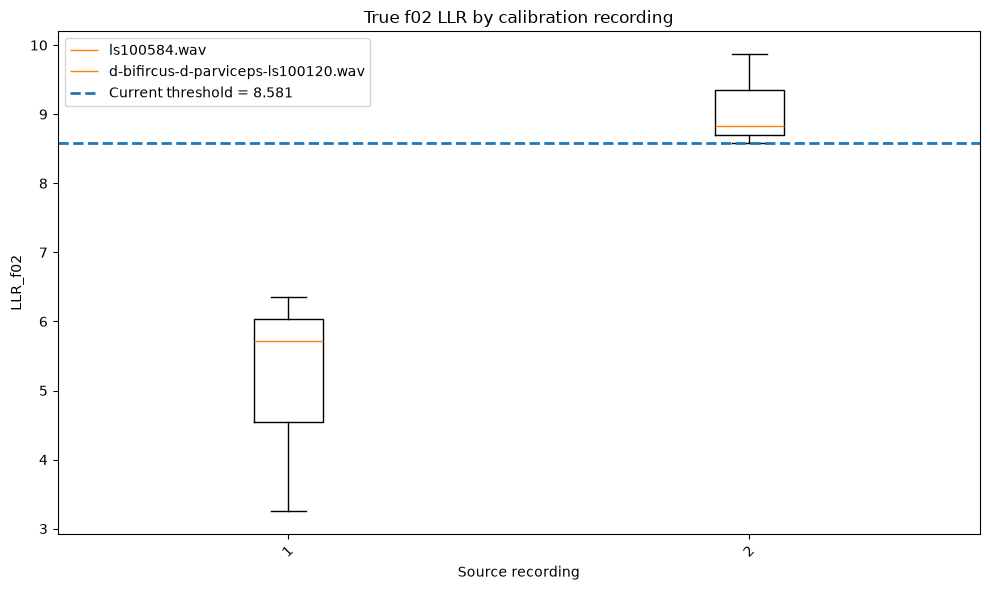

In [19]:
recording_order = (
    f02_by_recording[
        "recording_group"
    ]
    .tolist()
)

plot_data = [
    true_f02.loc[
        true_f02[
            "recording_group"
        ] == recording,
        f"llr_{TARGET_CODE}",
    ].to_numpy()
    for recording in recording_order
]

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.boxplot(
    plot_data,
    label=recording_order,
    showfliers=True,
)

ax.axhline(
    F02_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Current threshold = {F02_THRESHOLD:.3f}",
)

ax.set(
    title="True f02 LLR by calibration recording",
    xlabel="Source recording",
    ylabel="LLR_f02",
)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.legend()

plt.tight_layout()
plt.show()

## 7. Which alternative models are closest to true f02 calls?

For each true `f02` call, inspect the scores of all GMMs.

Two diagnostics are useful:

- the strongest non-f02 competitor;
- the margin between the `f02` score and that strongest competitor.

The detector LLR uses the **median** alternative rather than the strongest alternative, so both the
winner margin and the median-based LLR are shown.

In [20]:
score_columns = [
    column
    for column in scores.columns
    if column.startswith(
        "score_"
    )
]

MODEL_CODES = tuple(
    column.replace(
        "score_",
        "",
        1,
    )
    for column in score_columns
)

alternative_codes = [
    code
    for code in MODEL_CODES
    if code != TARGET_CODE
]

true_f02_detail = (
    scores[
        scores[
            "true_code"
        ] == TARGET_CODE
    ]
    .copy()
)

def alternative_diagnostics(row):
    alternative_scores = {
        code: float(
            row[
                f"score_{code}"
            ]
        )
        for code in alternative_codes
    }

    strongest_code = max(
        alternative_scores,
        key=alternative_scores.get,
    )

    strongest_score = (
        alternative_scores[
            strongest_code
        ]
    )

    median_alt = float(
        np.median(
            list(
                alternative_scores.values()
            )
        )
    )

    f02_score = float(
        row[
            f"score_{TARGET_CODE}"
        ]
    )

    return pd.Series({
        "strongest_alternative":
            strongest_code,
        "strongest_alternative_score":
            strongest_score,
        "f02_vs_strongest_margin":
            f02_score
            - strongest_score,
        "alternative_median":
            median_alt,
        "recomputed_llr_f02":
            f02_score
            - median_alt,
    })

alt_diag = (
    true_f02_detail
    .apply(
        alternative_diagnostics,
        axis=1,
    )
)

true_f02_detail = pd.concat(
    [
        true_f02_detail,
        alt_diag,
    ],
    axis=1,
)

assert np.allclose(
    true_f02_detail[
        "recomputed_llr_f02"
    ],
    true_f02_detail[
        f"llr_{TARGET_CODE}"
    ],
)

display(
    true_f02_detail[
        [
            "call_id",
            "wav",
            "hypothesis",
            f"score_{TARGET_CODE}",
            "strongest_alternative",
            "strongest_alternative_score",
            "f02_vs_strongest_margin",
            "alternative_median",
            f"llr_{TARGET_CODE}",
        ]
    ]
    .sort_values(
        f"llr_{TARGET_CODE}"
    )
    .round(4)
)

,call_id,wav,hypothesis,score_f02,strongest_alternative,strongest_alternative_score,f02_vs_strongest_margin,alternative_median,llr_f02
26,call_0172,LS100584.WAV,f05,37.9558,f05,38.1128,-0.1570,34.7050,3.2508
33,call_0179,LS100584.WAV,f02,39.3761,f03,36.6223,2.7538,35.6749,3.7012
31,call_0177,LS100584.WAV,f02,41.4313,f06,39.8650,1.5663,37.6822,3.7491
39,call_0185,LS100584.WAV,f02,40.6356,f06,38.2895,2.3461,36.2911,4.3445
27,call_0173,LS100584.WAV,f02,37.9661,f05,36.6988,1.2674,33.6214,4.3447
36,call_0182,LS100584.WAV,f02,41.1908,f06,38.1189,3.0719,36.6484,4.5424
37,call_0183,LS100584.WAV,f02,39.5257,f06,37.4950,2.0307,34.6861,4.8396
30,call_0176,LS100584.WAV,f02,40.7600,f05,39.5537,1.2063,35.6677,5.0923
24,call_0170,LS100584.WAV,f05,38.3841,f05,39.0091,-0.6250,33.0210,5.3631
38,call_0184,LS100584.WAV,f02,40.1362,f05,36.1215,4.0147,34.6113,5.5249


In [21]:
competitor_counts = (
    true_f02_detail[
        "strongest_alternative"
    ]
    .value_counts()
    .rename_axis(
        "strongest_alternative"
    )
    .reset_index(
        name="n_true_f02_calls"
    )
)

display(
    competitor_counts
)

,strongest_alternative,n_true_f02_calls
0,f05,18
1,f06,5
2,f03,1


## 8. Threshold sweep: verification-only f02 ROC behavior

This sweep asks:

> If `LLR_f02 >= threshold` is treated as a one-vs-all `f02` verification event, what TPR/FPR/precision
> results?

This matches the score-level ROC question used for calibration.

It does **not** yet include the requirement that `f02` must be the winning GMM hypothesis.

In [22]:
y_true = (
    scores[
        "true_code"
    ] == TARGET_CODE
).to_numpy()

llr = (
    scores[
        f"llr_{TARGET_CODE}"
    ]
    .to_numpy()
)

candidate_thresholds = np.unique(
    np.concatenate([
        llr,
        np.array(
            [
                F02_THRESHOLD,
                llr.min() - 1e-9,
                llr.max() + 1e-9,
            ]
        ),
    ])
)

sweep_rows = []

for threshold in candidate_thresholds:

    y_pred = (
        llr >= threshold
    )

    TP = int(
        np.sum(
            y_true
            & y_pred
        )
    )

    FN = int(
        np.sum(
            y_true
            & ~y_pred
        )
    )

    FP = int(
        np.sum(
            ~y_true
            & y_pred
        )
    )

    TN = int(
        np.sum(
            ~y_true
            & ~y_pred
        )
    )

    recall = (
        TP / (TP + FN)
    )

    fpr = (
        FP / (FP + TN)
    )

    precision = (
        TP / (TP + FP)
        if (TP + FP)
        else np.nan
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (
            np.isfinite(
                precision
            )
            and (
                precision + recall
            ) > 0
        )
        else np.nan
    )

    sweep_rows.append({
        "threshold":
            float(
                threshold
            ),
        "TP":
            TP,
        "FN":
            FN,
        "FP":
            FP,
        "TN":
            TN,
        "recall_TPR":
            recall,
        "FPR":
            fpr,
        "precision":
            precision,
        "F1":
            f1,
    })

verification_sweep = (
    pd.DataFrame(
        sweep_rows
    )
    .sort_values(
        "threshold",
        ascending=False,
    )
    .reset_index(drop=True)
)

current_verification_row = (
    verification_sweep.iloc[
        (
            verification_sweep[
                "threshold"
            ]
            - F02_THRESHOLD
        )
        .abs()
        .argmin()
    ]
)

print("Current f02 threshold:")
display(
    pd.DataFrame(
        [
            current_verification_row
        ]
    ).round(4)
)

Current f02 threshold:


,threshold,TP,FN,FP,TN,recall_TPR,FPR,precision,F1
5,8.5813,3.0,21.0,2.0,356.0,0.125,0.0056,0.6,0.2069


## 9. Diagnostic operating points at several FPR ceilings

For each FPR ceiling, choose the threshold with the highest recall and then the highest threshold in a
tie.

These are **candidate diagnostics**, not automatic replacements.

In [23]:
FPR_CEILINGS = (
    0.00,
    0.005,
    0.01,
    0.02,
    0.05,
    0.10,
)

operating_rows = []

for max_fpr in FPR_CEILINGS:

    feasible = (
        verification_sweep[
            verification_sweep[
                "FPR"
            ]
            <= max_fpr
            + 1e-12
        ]
        .copy()
    )

    if feasible.empty:
        continue

    best_recall = float(
        feasible[
            "recall_TPR"
        ].max()
    )

    chosen = (
        feasible[
            np.isclose(
                feasible[
                    "recall_TPR"
                ],
                best_recall,
            )
        ]
        .sort_values(
            "threshold",
            ascending=False,
        )
        .iloc[0]
    )

    operating_rows.append({
        "max_FPR_constraint":
            max_fpr,
        **chosen.to_dict(),
    })

diagnostic_operating_points = pd.DataFrame(
    operating_rows
)

display(
    diagnostic_operating_points.round(4)
)

,max_FPR_constraint,threshold,TP,FN,FP,TN,recall_TPR,FPR,precision,F1
0,0.000,9.9249,0.0,24.0,0.0,358.0,0.0000,0.0000,NaN,NaN
1,0.005,9.8685,1.0,23.0,1.0,357.0,0.0417,0.0028,0.5,0.0769
2,0.010,8.5813,3.0,21.0,2.0,356.0,0.1250,0.0056,0.6,0.2069
3,0.020,8.5813,3.0,21.0,2.0,356.0,0.1250,0.0056,0.6,0.2069
4,0.050,8.5813,3.0,21.0,2.0,356.0,0.1250,0.0056,0.6,0.2069
5,0.100,8.5813,3.0,21.0,2.0,356.0,0.1250,0.0056,0.6,0.2069


## 10. End-to-end f02 threshold sweep

The deployed detector first selects the highest-scoring GMM. Therefore an `f02` detection can occur only
when:

1. the GMM hypothesis is `f02`;
2. `LLR_f02 >= threshold`.

This sweep measures the threshold's actual effect on the final `f02` detector while keeping **every
other class and every GMM unchanged**.

In [24]:
hypothesis_is_f02 = (
    scores[
        "hypothesis"
    ] == TARGET_CODE
).to_numpy()

end_to_end_rows = []

for threshold in candidate_thresholds:

    detector_positive = (
        hypothesis_is_f02
        & (
            llr
            >= threshold
        )
    )

    TP = int(
        np.sum(
            y_true
            & detector_positive
        )
    )

    FN = int(
        np.sum(
            y_true
            & ~detector_positive
        )
    )

    FP = int(
        np.sum(
            ~y_true
            & detector_positive
        )
    )

    TN = int(
        np.sum(
            ~y_true
            & ~detector_positive
        )
    )

    recall = (
        TP / (TP + FN)
    )

    fpr = (
        FP / (FP + TN)
    )

    precision = (
        TP / (TP + FP)
        if (TP + FP)
        else np.nan
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (
            np.isfinite(
                precision
            )
            and (
                precision + recall
            ) > 0
        )
        else np.nan
    )

    end_to_end_rows.append({
        "threshold":
            float(
                threshold
            ),
        "TP":
            TP,
        "FN":
            FN,
        "FP":
            FP,
        "TN":
            TN,
        "recall":
            recall,
        "FPR":
            fpr,
        "precision":
            precision,
        "F1":
            f1,
    })

end_to_end_sweep = (
    pd.DataFrame(
        end_to_end_rows
    )
    .sort_values(
        "threshold",
        ascending=False,
    )
    .reset_index(drop=True)
)

current_end_to_end = (
    end_to_end_sweep.iloc[
        (
            end_to_end_sweep[
                "threshold"
            ]
            - F02_THRESHOLD
        )
        .abs()
        .argmin()
    ]
)

print("Current end-to-end f02 operating point:")
display(
    pd.DataFrame(
        [
            current_end_to_end
        ]
    ).round(4)
)

Current end-to-end f02 operating point:


,threshold,TP,FN,FP,TN,recall,FPR,precision,F1
5,8.5813,3.0,21.0,2.0,356.0,0.125,0.0056,0.6,0.2069


## 11. End-to-end candidate operating points

Again, these are diagnostic. No threshold JSON is modified.

In [25]:
end_to_end_operating_rows = []

for max_fpr in FPR_CEILINGS:

    feasible = (
        end_to_end_sweep[
            end_to_end_sweep[
                "FPR"
            ]
            <= max_fpr
            + 1e-12
        ]
        .copy()
    )

    if feasible.empty:
        continue

    # Here F1 is useful as a descriptive summary, but recall remains important
    # because presence/absence detection needs at least one true accepted call.
    best_f1 = float(
        feasible[
            "F1"
        ].fillna(-np.inf)
        .max()
    )

    chosen = (
        feasible[
            np.isclose(
                feasible[
                    "F1"
                ].fillna(-np.inf),
                best_f1,
            )
        ]
        .sort_values(
            [
                "recall",
                "threshold",
            ],
            ascending=[
                False,
                False,
            ],
        )
        .iloc[0]
    )

    end_to_end_operating_rows.append({
        "max_FPR_constraint":
            max_fpr,
        **chosen.to_dict(),
    })

end_to_end_operating_points = pd.DataFrame(
    end_to_end_operating_rows
)

display(
    end_to_end_operating_points.round(4)
)

,max_FPR_constraint,threshold,TP,FN,FP,TN,recall,FPR,precision,F1
0,0.000,9.9249,0.0,24.0,0.0,358.0,0.0000,0.0000,NaN,NaN
1,0.005,9.8685,1.0,23.0,1.0,357.0,0.0417,0.0028,0.50,0.0769
2,0.010,3.7012,22.0,2.0,3.0,355.0,0.9167,0.0084,0.88,0.8980
3,0.020,3.7012,22.0,2.0,3.0,355.0,0.9167,0.0084,0.88,0.8980
4,0.050,3.7012,22.0,2.0,3.0,355.0,0.9167,0.0084,0.88,0.8980
5,0.100,3.7012,22.0,2.0,3.0,355.0,0.9167,0.0084,0.88,0.8980


## 12. Plot threshold trade-offs

The current threshold is marked, but the plot is diagnostic only.

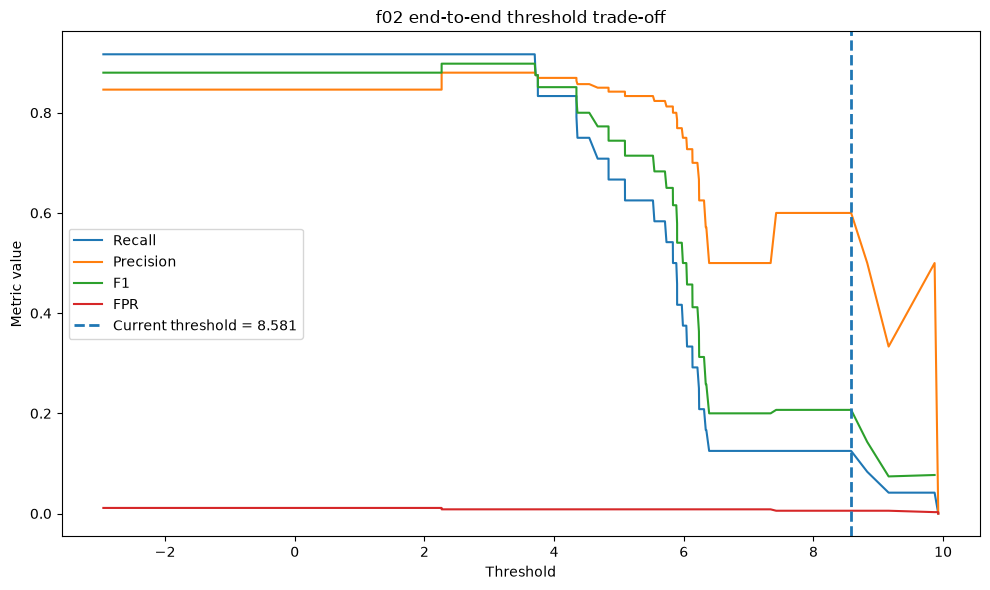

In [26]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

ordered = (
    end_to_end_sweep
    .sort_values(
        "threshold"
    )
)

ax.plot(
    ordered[
        "threshold"
    ],
    ordered[
        "recall"
    ],
    label="Recall",
)

ax.plot(
    ordered[
        "threshold"
    ],
    ordered[
        "precision"
    ],
    label="Precision",
)

ax.plot(
    ordered[
        "threshold"
    ],
    ordered[
        "F1"
    ],
    label="F1",
)

ax.plot(
    ordered[
        "threshold"
    ],
    ordered[
        "FPR"
    ],
    label="FPR",
)

ax.axvline(
    F02_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label=f"Current threshold = {F02_THRESHOLD:.3f}",
)

ax.set(
    title="f02 end-to-end threshold trade-off",
    xlabel="Threshold",
    ylabel="Metric value",
)

ax.legend()

plt.tight_layout()
plt.show()

## 13. Identify thresholds around the positive-call LLR distribution

This table reports where the true `f02` calls sit. It can reveal whether the current threshold lies above
most of the positive distribution.

In [27]:
positive_quantiles = (
    positive_llr
    .quantile(
        [
            0.00,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            1.00,
        ]
    )
    .rename(
        "LLR_f02"
    )
    .reset_index()
    .rename(
        columns={
            "index":
                "quantile",
        }
    )
)

positive_quantiles[
    "above_current_threshold"
] = (
    positive_quantiles[
        "LLR_f02"
    ]
    >= F02_THRESHOLD
)

display(
    positive_quantiles.round(4)
)

,quantile,LLR_f02,above_current_threshold
0,0.00,3.2508,False
1,0.10,3.9277,False
2,0.25,4.7653,False
3,0.50,5.8580,False
4,0.75,6.2163,False
5,0.90,7.9112,False
6,1.00,9.8685,True


## 14. Save diagnostic outputs

In [28]:
distribution_summary.to_csv(
    RESULTS_DIR
    / "f02_llr_distribution_summary.csv",
    index=False,
)

negative_by_species.to_csv(
    RESULTS_DIR
    / "f02_negative_llr_by_true_species.csv",
    index=False,
)

top_negative_calls.to_csv(
    RESULTS_DIR
    / "f02_top_negative_calls.csv",
    index=False,
)

true_f02.to_csv(
    RESULTS_DIR
    / "f02_true_calls_failure_modes.csv",
    index=False,
)

f02_by_recording.to_csv(
    RESULTS_DIR
    / "f02_true_calls_by_recording.csv",
    index=False,
)

true_f02_detail.to_csv(
    RESULTS_DIR
    / "f02_true_call_score_decomposition.csv",
    index=False,
)

competitor_counts.to_csv(
    RESULTS_DIR
    / "f02_strongest_competitors.csv",
    index=False,
)

verification_sweep.to_csv(
    RESULTS_DIR
    / "f02_verification_threshold_sweep.csv",
    index=False,
)

diagnostic_operating_points.to_csv(
    RESULTS_DIR
    / "f02_verification_candidate_operating_points.csv",
    index=False,
)

end_to_end_sweep.to_csv(
    RESULTS_DIR
    / "f02_end_to_end_threshold_sweep.csv",
    index=False,
)

end_to_end_operating_points.to_csv(
    RESULTS_DIR
    / "f02_end_to_end_candidate_operating_points.csv",
    index=False,
)

positive_quantiles.to_csv(
    RESULTS_DIR
    / "f02_positive_llr_quantiles.csv",
    index=False,
)

print("Saved diagnostic outputs:")

for path in sorted(
    RESULTS_DIR.iterdir()
):
    print(
        f"  {path.name:<52} "
        f"{path.stat().st_size / 1e6:>8.3f} MB"
    )

Saved diagnostic outputs:
  f02_end_to_end_candidate_operating_points.csv           0.001 MB
  f02_end_to_end_threshold_sweep.csv                      0.037 MB
  f02_llr_distribution_summary.csv                        0.000 MB
  f02_negative_llr_by_true_species.csv                    0.001 MB
  f02_positive_llr_quantiles.csv                          0.000 MB
  f02_strongest_competitors.csv                           0.000 MB
  f02_top_negative_calls.csv                              0.006 MB
  f02_true_call_score_decomposition.csv                   0.012 MB
  f02_true_calls_by_recording.csv                         0.000 MB
  f02_true_calls_failure_modes.csv                        0.004 MB
  f02_verification_candidate_operating_points.csv         0.001 MB
  f02_verification_threshold_sweep.csv                    0.037 MB


## 15. Interpretation guide

Do not change the detector threshold until the outputs above establish which situation applies.

### Case A — one recording dominates the failures

If almost all rejected true `f02` calls come from one WAV, the issue is likely recording-domain
variation. A lower threshold may improve that calibration recording but may not generalize.

### Case B — one negative species dominates high f02 LLR

If a specific species generates most high negative scores, the important problem is class confusion.
Threshold adjustment alone trades false positives against recall without fixing the underlying overlap.

### Case C — f02 wins identification but its LLR is systematically low

Then the GMM is often ranking `f02` correctly, but the median-alternative verification statistic is
poorly separated for this class. This would justify testing an alternative calibration statistic in a
separate experiment, not silently replacing the current detector.

### Case D — a moderate threshold reduction improves recall with little FPR cost

That would support considering a different operating point for `f02`, especially because the paper
explicitly treats threshold choice as an application-dependent trade-off and reports manual
fine-tuning after the initial ROC operating points.

Even in Case D, any revised threshold must be labelled as a **project calibration decision**, not as a
paper value.

## Detector state

This notebook does **not** overwrite:

- `models/gmm_robust_final/thresholds.json`;
- any GMM model;
- notebook-07 calibration outputs.

The frozen detector remains unchanged after running this notebook.